# 02 - The Jacobian of the whole scan

Notebook 01 built the local Jacobian $A_R$ at **one** scan position. This notebook stacks
every position into the single operator the measurement actually realises, and
diagonalises it.

The question it answers: **which changes to the specimen would this scan have seen, and
which would it have missed entirely?**

## The forward model, and the symbols used throughout

A 4D-STEM scan records one diffraction pattern per probe position. Change the specimen a
little and every pattern changes a little. The Jacobian is the matrix of those changes.

| symbol | meaning |
|---|---|
| $O_0$ | the base object, a pure phase object on the object grid |
| $h$ | a small **real** phase perturbation of it, so the perturbed object is $O_1 = O_0 e^{ih}$ |
| $R$ | one scan position; the scan has $M$ of them |
| $P_R$ | the probe, centred at $R$ |
| $\psi_{0,R} = P_R\,O_0$ | the **exit wave** at that position, on the object grid |
| $\mathcal{F}$ | the centred 2-D DFT |
| $\mathrm{crop}$ | keep the central detector pixels - what `max_angle="valid"` returns |
| $\Psi_{0,R} = \mathrm{crop}\,\mathcal{F}\{\psi_{0,R}\}$ | the **camera wave**; the recorded intensity is $\lvert\Psi_{0,R}\rvert^2$ |

To first order in $h$, the intensity recorded at position $R$ changes by

$$A_R\,h \;=\; -2\,\mathrm{Im}\!\left[\overline{\Psi_{0,R}}\;\mathrm{crop}\,\mathcal{F}\{\psi_{0,R}\,h\}\right].$$

$A_R$ is a matrix: it takes a perturbation over the object and returns a change over the
detector. Notebook 01 stopped here, at one position.

## Stacking the scan

A ptychographic measurement is all of the patterns at once, so the operator of the
experiment is the row-stack of the per-position ones:

$$A \;=\; \begin{bmatrix} A_{R_1} \\ A_{R_2} \\ \vdots \\ A_{R_M}\end{bmatrix}$$

$A$ has **one row per (scan position, detector pixel)** and **one column per object
pixel**. Stacking rows is the right thing because the positions are independent
measurements of the same object: their responses add up in the least-squares sense, which
is exactly what the stack encodes.

## What its singular value decomposition means

Take $A = U\Sigma V^{\mathsf T}$. The columns of $V$ are **real phase perturbations of the
object**, and mode $i$ produces a detector response of norm $\sigma_i$ per unit norm of
perturbation. So:

* $v_1$ is the change this experiment is most sensitive to;
* a mode whose $\sigma_i$ has collapsed is one the experiment barely responds to;
* the null space of $A$ is, to linear order, exactly what this scan **cannot measure at
  all** - no reconstruction algorithm can recover it, because nothing in the data depends
  on it.

Unlike notebook 01, these modes belong to the whole experiment rather than to one probe
position, so they describe the scan as a measuring instrument.

## Why $A$ is never written down, and the two routes used instead

$A$ has $M\times(\text{detector pixels})$ rows and $(\text{object pixels})$ columns. For a
few hundred positions on a $10^4$-pixel detector that is terabytes, so $A$ is never
formed. Two ways around it, both used below, answering different ends of the spectrum:

* **Gram route - the complete spectrum, on a window.** Diagonalising $A$ is the same as
  diagonalising $A^{\mathsf T}A=\sum_R A_R^{\mathsf T}A_R$, which lives in object space
  only and is accumulated one position at a time. Its eigenvectors are the columns of $V$
  and its eigenvalues are $\sigma_i^2$. This reaches the blind end, but object space has
  to be small enough to square and diagonalise, so it runs on a **window** of object
  pixels - that is, it asks what the scan can see of a perturbation confined to that
  patch. The detector sum inside it is evaluated in closed form by two FFTs instead of a
  matrix product: exact, about ten times faster, and derived and verified in
  `fft_structured_gram.py`.
* **Matrix-free route - the leading modes, at full resolution.** Randomized subspace
  iteration needs only $h\mapsto Ah$ and $g\mapsto A^{\mathsf T}g$, which are FFTs. It
  places no restriction on where in the object the modes live, but it reaches only the
  strongly sensed end; the iteration suppresses small $\sigma$ by construction.

## Two things to keep in mind when reading the output

**There is a numerical floor, and it is not physics.** Forming $A^{\mathsf T}A$ squares
the condition number, so the smallest singular values recoverable from it are about
$\sqrt{\varepsilon}\,\sigma_1$ - near $10^{-8}\sigma_1$ in float64, $10^{-5}\sigma_1$ in
float32. That floor is drawn on every spectrum plot. Values sitting on it are below the
arithmetic, not measured.

**The model here is the best case.** Multislice, partial coherence, finite dose and
probe-position error are all absent, so $A$ is the Jacobian of a noiseless, single-slice,
coherent experiment. A real measurement can only be blinder than this, never sharper -
in particular, shot noise raises the effective floor far above the numerical one.

In [2]:
import sys
import pickle
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import linearized_jacobian as lj
import fft_structured_gram as fsg

torch.backends.cuda.matmul.allow_tf32 = False   # the Gram needs every bit it can get

print("notebook dir :", NOTEBOOK_DIR)
print("modules      :", lj.__file__)
print("             :", fsg.__file__)
print("torch        :", torch.__version__)
print("cuda device  :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

notebook dir : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
modules      : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/linearized_jacobian.py
             : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho/fft_structured_gram.py
torch        : 2.14.1+cu130
cuda device  : NVIDIA GeForce RTX 5090


## Configuration

The only cell to edit per experiment.

Two knobs cost real time. `SCAN_STEP_SIZE_ANG` sets how many positions go into the stack,
and everything downstream is linear in that. `GRAM_WINDOW_WIDTH_PX` sets the dense Gram,
which costs $W^4 \times (\text{detector pixels})$ flops - doubling the window is
$16\times$ the time. The window should be at least as wide as the structure whose
detectability is in question.

`SCAN_ENDPOINT` matters more than it looks. The simulation cell is periodic, so a scan
built with `endpoint=True` puts its last row and column back on top of its first. Those
positions then enter the stack twice and the corner four times, $A^{\mathsf T}A$ carries
that weight, and the leading modes pile up on the over-counted boundary - which is a
property of the scan bookkeeping, not of the optics. Leave it `False` unless the
duplicates are wanted.

In [3]:
PHASE_CACHE_PATH = NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl"
PHASE_CACHE_KEY_BASE = "base"
PHASE_CACHE_KEY_EXCITED = "excited"   # only used to check the linearization, never to build A

ACC_VOLTAGE_EV = 60e3
PROBE_SEMIANGLE_MRAD = 30.0
PROBE_DEFOCUS_ANG = 0.0
SLICE_THICKNESS_ANG = 1.0          # bookkeeping slice for a projected phase object

SCAN_STEP_SIZE_ANG = 0.5           # requested step; GridScan rounds it to fit the extent
SCAN_REGION_START = (7, 7)         # Bottom-left corner of the scan region, in Angstrom
SCAN_REGION_END = (17, 17)         # Top-right corner of the scan region

# TORCH_DEVICE = "cpu"
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --- dense Gram over a window of object pixels: the complete spectrum -------------
GRAM_WINDOW_WIDTH_PX = 64          # square window of object pixels, centred on the field of view
GRAM_USE_FLOAT64 = True            # float32 floors out near 1e-5 * sigma_1; float64 near 1e-8
N_MODES_SHOWN = 6                  # panels per mode figure, at each end of the spectrum

GRAM_ROW_BLOCK = 2048              # object rows of the Gram built at a time
GRAM_SYMMETRIC = True              # compute the lower triangle only and mirror it

# --- matrix-free randomized iteration at full object resolution ------------------
FULL_RESOLUTION_N_MODES = 8
FULL_RESOLUTION_N_OVERSAMPLE = 60
FULL_RESOLUTION_N_ITERATIONS = 6
SCAN_CHUNK_SIZE = 8                # scan positions held on the device at once
RANDOM_SEED = 0

print("device                     :", TORCH_DEVICE)
print("phase cache                :", PHASE_CACHE_PATH.name)
print("requested scan step [A]    :", SCAN_STEP_SIZE_ANG)
print("scan region [A]            :", SCAN_REGION_START, "to", SCAN_REGION_END)
print("Gram window [object px]    :", GRAM_WINDOW_WIDTH_PX,
      "  precision:", "float64" if GRAM_USE_FLOAT64 else "float32")
print("Gram row block             :", GRAM_ROW_BLOCK, "  symmetric:", GRAM_SYMMETRIC)

device                     : cuda
phase cache                : bcenters_base_excited_phases_wide_fov.pkl
requested scan step [A]    : 0.5
scan region [A]            : (7, 7) to (17, 17)
Gram window [object px]    : 64   precision: float64
Gram row block             : 2048   symmetric: True


## Build the object, the probe and the scan

Built here from the cached phase, the same way notebook 01 does it, so the probe settings
and the scan are parameters of this notebook rather than properties of a saved file. Only
the **base** phase enters the operator; the excited one is loaded solely to check the
linearization further down.

In [4]:
with open(PHASE_CACHE_PATH, "rb") as handle:
    phase_cache = pickle.load(handle)

phase_base = np.asarray(phase_cache[PHASE_CACHE_KEY_BASE], dtype=np.float32)
phase_excited = np.asarray(phase_cache[PHASE_CACHE_KEY_EXCITED], dtype=np.float32)
object_x_ang = np.asarray(phase_cache["x"], dtype=np.float32)
object_x_ang -= object_x_ang[0]
object_y_ang = np.asarray(phase_cache["y"], dtype=np.float32)
object_y_ang -= object_y_ang[0]
object_sampling_ang = (
    float(object_y_ang[1] - object_y_ang[0]),
    float(object_x_ang[1] - object_x_ang[0]),
)
object_base = np.exp(1j * phase_base).astype(np.complex64)

potential = lj.make_phase_potential(
    phase_base, ACC_VOLTAGE_EV, SLICE_THICKNESS_ANG, object_sampling_ang
)
probe = lj.make_probe(ACC_VOLTAGE_EV, PROBE_SEMIANGLE_MRAD, PROBE_DEFOCUS_ANG, potential)

n_object_y, n_object_x = phase_base.shape
field_of_view_ang = tuple(float(v) for v in potential.extent)
detector_shape = lj.valid_detector_shape(probe)
n_detector_y, n_detector_x = detector_shape
detector_sampling_inv_ang = (1.0 / field_of_view_ang[1], 1.0 / field_of_view_ang[0])
electron_wavelength_ang = float(probe.wavelength)

scan_positions_xy_ang = lj.grid_scan_positions_ang(
    potential, SCAN_STEP_SIZE_ANG, start=SCAN_REGION_START, end=SCAN_REGION_END
)
scan_shape = scan_positions_xy_ang.shape[:2]
scan_positions_flat_xy_ang = scan_positions_xy_ang.reshape(-1, 2).astype(np.float64)
n_scan_positions = len(scan_positions_flat_xy_ang)
realised_scan_step_ang = float(np.diff(np.unique(scan_positions_flat_xy_ang[:, 0]))[0])

# Two positions that coincide modulo the periodic cell are one measurement counted twice.
scan_positions_wrapped_ang = np.round(
    np.mod(np.round(scan_positions_flat_xy_ang / np.array(field_of_view_ang), 6), 1.0)
    * np.array(field_of_view_ang), 4
)
n_distinct_scan_positions = len(np.unique(scan_positions_wrapped_ang, axis=0))

probe_by_scan_torch = torch.as_tensor(
    np.asarray(
        probe.build(scan=scan_positions_flat_xy_ang.tolist()).compute().array
    ).astype(np.complex64),
    device=TORCH_DEVICE,
)
object_base_torch = torch.as_tensor(object_base, device=TORCH_DEVICE)
exit_wave_by_scan = (probe_by_scan_torch * object_base_torch).to(torch.complex128)

object_extent_ang = [
    float(object_x_ang[0]), float(object_x_ang[-1]),
    float(object_y_ang[0]), float(object_y_ang[-1]),
]
dense_stack_shape = (n_scan_positions * n_detector_y * n_detector_x, n_object_y * n_object_x)
matrix_free_peak_memory_gb = (
    8 * n_scan_positions * (FULL_RESOLUTION_N_MODES + FULL_RESOLUTION_N_OVERSAMPLE)
    * n_detector_y * n_detector_x / 1e9
)

print("object grid [px]           :", (n_object_y, n_object_x))
print("object sampling [A/px]     :", tuple(round(v, 5) for v in object_sampling_ang))
print("field of view [A]          :", tuple(round(v, 3) for v in field_of_view_ang))
print("detector [px]              :", detector_shape)
print("detector sampling [1/A]    :", tuple(round(v, 5) for v in detector_sampling_inv_ang))
print("wavelength [A]             :", round(electron_wavelength_ang, 5))
print()
print("scan grid                  :", scan_shape, "=", n_scan_positions, "positions")
print(f"scan step requested -> realised [A] : {SCAN_STEP_SIZE_ANG} -> "
      f"{realised_scan_step_ang:.4f}")
if n_distinct_scan_positions < n_scan_positions:
    print(f"WARNING  only {n_distinct_scan_positions} of {n_scan_positions} positions are "
          f"distinct modulo the periodic cell.")
    print(f"         {n_scan_positions - n_distinct_scan_positions} are counted twice, which "
          f"biases the spectrum towards the field-of-view")
    print("         boundary -- set SCAN_ENDPOINT = False.")
else:
    print("every scan position is distinct modulo the periodic cell")
print()
print(f"dense stacked A would be   : {dense_stack_shape[0]:,} x {dense_stack_shape[1]:,}"
      f"  =  {4 * dense_stack_shape[0] * dense_stack_shape[1] / 1e12:.2f} TB in float32")
print(f"matrix-free peak memory    : {matrix_free_peak_memory_gb:.1f} GB on the device "
      f"at this scan and sketch size")

object grid [px]           : (251, 251)
object sampling [A/px]     : (0.096, 0.096)
field of view [A]          : (24.096, 24.096)
detector [px]              : (119, 119)
detector sampling [1/A]    : (0.0415, 0.0415)
wavelength [A]             : 0.04866

scan grid                  : (21, 21) = 441 positions
scan step requested -> realised [A] : 0.5 -> 0.5000
every scan position is distinct modulo the periodic cell

dense stacked A would be   : 6,245,001 x 63,001  =  1.57 TB in float32
matrix-free peak memory    : 3.4 GB on the device at this scan and sketch size


## The probe and the scan, before anything is read off the spectrum

The whole operator is built out of these. A mode figure can look structured while the
probe behind it is wrong, and no object-space quantity will say so.

Two things to check in the scan itself, because both land directly in the spectrum:

* **Duplicate positions.** A `GridScan` built with `endpoint=True` on a periodic cell puts
  its last row and column back on top of its first, so those positions enter the stack
  twice and the corner four times. $A^{\mathsf T}A$ then carries that weight, and the
  leading modes pile up on the over-counted boundary - a property of the scan bookkeeping,
  not of the optics. The duplicates are detected modulo the cell and dropped above.
* **Coverage.** $\sum_R |P_R|^2$ is how much illumination each object pixel receives over
  the whole scan. A focused probe stepped more coarsely than its own width leaves this
  ragged, and a ragged coverage map puts structure at the scan period into every mode.
  Read the max/min ratio next to the panel: it is the honest statement of how much of the
  spectrum belongs to the sampling rather than to the probe.

probe FWHM, measured : 0.839 A   (ideal Airy 0.51 lambda/alpha : 0.834 A, +0.6%)
scan step            : 0.500 A  =  0.60 x the probe FWHM


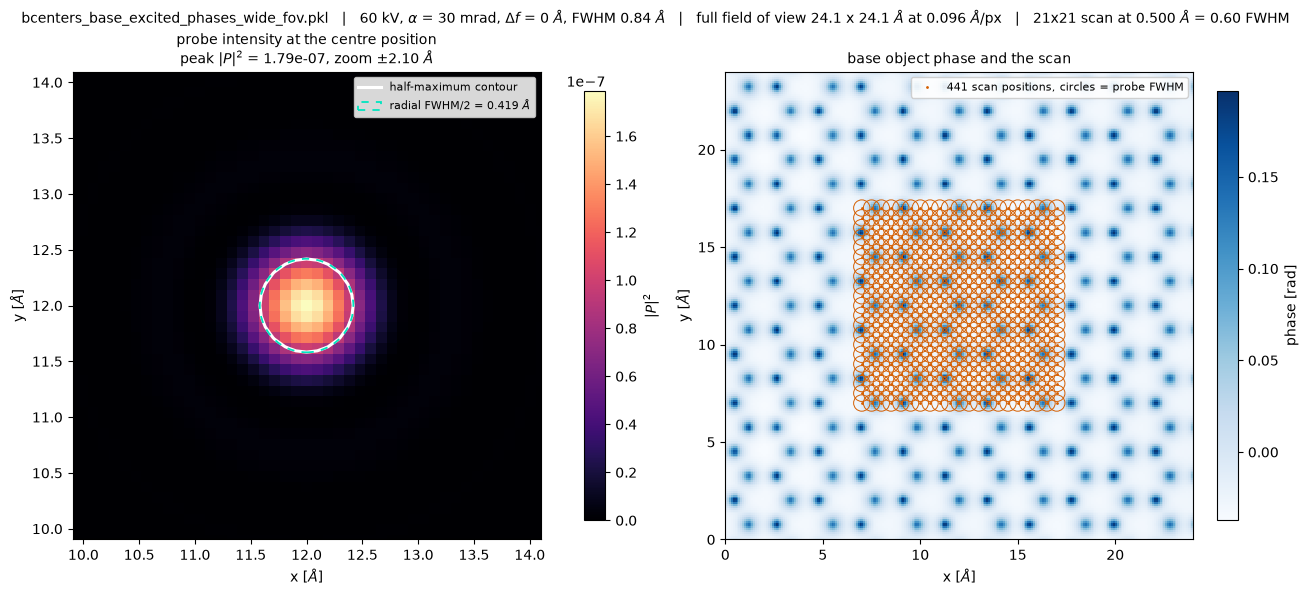

In [5]:
from matplotlib.collections import EllipseCollection

centre_scan_index = int(np.argmin(np.linalg.norm(
    scan_positions_flat_xy_ang - np.array(field_of_view_ang) / 2.0, axis=1
)))
probe_centre_intensity = (probe_by_scan_torch[centre_scan_index].abs() ** 2).cpu().numpy()
scan_positions_object_frame_ang = (
    scan_positions_flat_xy_ang + np.array([object_x_ang[0], object_y_ang[0]], dtype=np.float64)
)

# Probe width, measured rather than taken from the Airy formula: azimuthal average of
# |P|^2 about the peak pixel in half-pixel bins, interpolated for the half-maximum
# crossing.  Bins finer than the pixel grid can be empty, so drop them.
peak_row, peak_col = np.unravel_index(np.argmax(probe_centre_intensity),
                                      probe_centre_intensity.shape)
row_index, col_index = np.mgrid[0:probe_centre_intensity.shape[0],
                                0:probe_centre_intensity.shape[1]]
radius_from_peak_ang = np.hypot((row_index - peak_row) * object_sampling_ang[0],
                                (col_index - peak_col) * object_sampling_ang[1])
radial_bin_width_ang = object_sampling_ang[0] / 2.0
radial_bin_index = (radius_from_peak_ang / radial_bin_width_ang).astype(int).ravel()
radial_bin_count = np.bincount(radial_bin_index)
radial_bin_sum = np.bincount(radial_bin_index, weights=probe_centre_intensity.ravel())
occupied_bin = radial_bin_count > 0
radial_profile = radial_bin_sum[occupied_bin] / radial_bin_count[occupied_bin]
radial_bin_centre_ang = (
    (np.arange(len(radial_bin_count)) + 0.5) * radial_bin_width_ang
)[occupied_bin]

half_maximum = radial_profile.max() / 2.0
first_bin_below_half = int(np.argmax(radial_profile < half_maximum))
probe_fwhm_ang = 2.0 * float(np.interp(
    half_maximum,
    [radial_profile[first_bin_below_half], radial_profile[first_bin_below_half - 1]],
    [radial_bin_centre_ang[first_bin_below_half], radial_bin_centre_ang[first_bin_below_half - 1]],
))
# Airy intensity FWHM is 1.028 lambda / (2 NA); alpha is the full semiangle, so NA = alpha.
airy_fwhm_ang = 0.514 * electron_wavelength_ang / (PROBE_SEMIANGLE_MRAD * 1e-3)
probe_centre_object_frame_ang = (float(object_x_ang[peak_col]), float(object_y_ang[peak_row]))
probe_view_halfwidth_ang = 2.5 * probe_fwhm_ang

print(f"probe FWHM, measured : {probe_fwhm_ang:.3f} A"
      f"   (ideal Airy 0.51 lambda/alpha : {airy_fwhm_ang:.3f} A, "
      f"{probe_fwhm_ang / airy_fwhm_ang - 1:+.1%})")
print(f"scan step            : {realised_scan_step_ang:.3f} A"
      f"  =  {realised_scan_step_ang / probe_fwhm_ang:.2f} x the probe FWHM")

# With a finely sampled scan the circles would overlap into a blob, so draw a regular
# subset of them and say which.
circle_stride = 1
# circle_stride = max(1, int(np.ceil(np.sqrt(n_scan_positions / 225.0))))
circled_positions_ang = (
    scan_positions_xy_ang[::circle_stride, ::circle_stride].reshape(-1, 2)
    + np.array([object_x_ang[0], object_y_ang[0]], dtype=np.float64)
)
circle_label = ("circles = probe FWHM" if circle_stride == 1
                else f"circles = probe FWHM, every {circle_stride}th position")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.8), constrained_layout=True)

# --- 1. the probe.  Intensity, not amplitude, because that is what the FWHM was measured
# on, so the fitted circle has to land on the half-maximum contour.  A gap between them
# is an asymmetry a single radius would have hidden.
image = axes[0].imshow(probe_centre_intensity, extent=object_extent_ang, origin="lower",
                       cmap="magma", interpolation="nearest")
axes[0].contour(object_x_ang, object_y_ang, probe_centre_intensity,
                levels=[half_maximum], colors="white", linewidths=2.2, zorder=3)
axes[0].plot([], [], color="white", linewidth=2.2, label="half-maximum contour")
axes[0].add_patch(plt.Circle(
    probe_centre_object_frame_ang, probe_fwhm_ang / 2.0, fill=False,
    edgecolor="#00E5C0", linewidth=1.3, linestyle=(0, (4, 4)), zorder=4,
    label=f"radial FWHM/2 = {probe_fwhm_ang / 2:.3f} $\\AA$",
))
axes[0].set_xlim(probe_centre_object_frame_ang[0] - probe_view_halfwidth_ang,
                 probe_centre_object_frame_ang[0] + probe_view_halfwidth_ang)
axes[0].set_ylim(probe_centre_object_frame_ang[1] - probe_view_halfwidth_ang,
                 probe_centre_object_frame_ang[1] + probe_view_halfwidth_ang)
axes[0].legend(loc="upper right", fontsize=8, framealpha=0.85)
axes[0].set_title(f"probe intensity at the centre position\n"
                  f"peak $|P|^2$ = {probe_centre_intensity.max():.3g}, "
                  f"zoom $\\pm${probe_view_halfwidth_ang:.2f} $\\AA$", fontsize=10)
fig.colorbar(image, ax=axes[0], shrink=0.85, label="$|P|^2$")

# --- 2. the object and where the probe actually sits ----------------------------------
image = axes[1].imshow(phase_base, extent=object_extent_ang, origin="lower",
                       cmap="Blues", interpolation="nearest")
axes[1].add_collection(EllipseCollection(
    widths=probe_fwhm_ang, heights=probe_fwhm_ang, angles=0.0, units="xy",
    offsets=circled_positions_ang, offset_transform=axes[1].transData,
    facecolors="none", edgecolors="#D55E00", linewidths=0.7,
))
axes[1].plot(scan_positions_object_frame_ang[:, 0], scan_positions_object_frame_ang[:, 1],
             linestyle="none", marker=".", markersize=2.0, color="#D55E00",
             label=f"{n_scan_positions} scan positions, {circle_label}")
axes[1].legend(loc="upper right", fontsize=8, framealpha=0.9)
axes[1].set_xlim(object_extent_ang[0], object_extent_ang[1])
axes[1].set_ylim(object_extent_ang[2], object_extent_ang[3])
axes[1].set_title("base object phase and the scan", fontsize=10)
fig.colorbar(image, ax=axes[1], shrink=0.85, label="phase [rad]")

for ax in axes:
    ax.set_xlabel("x [$\\AA$]")
    ax.set_ylabel("y [$\\AA$]")
fig.suptitle(
    f"{PHASE_CACHE_PATH.name}   |   {ACC_VOLTAGE_EV/1e3:.0f} kV, "
    f"$\\alpha$ = {PROBE_SEMIANGLE_MRAD:.0f} mrad, "
    f"$\\Delta f$ = {PROBE_DEFOCUS_ANG:.0f} $\\AA$, FWHM {probe_fwhm_ang:.2f} $\\AA$   |   "
    f"full field of view {field_of_view_ang[0]:.1f} x {field_of_view_ang[1]:.1f} $\\AA$ "
    f"at {object_sampling_ang[0]:.3f} $\\AA$/px   |   {scan_shape[0]}x{scan_shape[1]} scan "
    f"at {realised_scan_step_ang:.3f} $\\AA$ = "
    f"{realised_scan_step_ang / probe_fwhm_ang:.2f} FWHM",
    fontsize=10,
)
plt.show()

## The operator

One transform convention, used for both factors of $A_R$. `linearized_jacobian` uses the
centred $\mathrm{fftshift}\circ\mathrm{fft2}\circ\mathrm{ifftshift}$; the corner-origin
$\mathrm{fftshift}\circ\mathrm{fft2}$ differs from it by a phase ramp across the
detector. The ramp cancels inside $A_R$ **only if the same convention is used for
$\Psi_{0,R}$ and for $\mathcal{F}\{\psi_{0,R}h\}$**, so mixing the two silently
produces a wrong operator.

In [6]:
def centered_dft_torch(array):
    """``fftshift(fft2(ifftshift(.)))`` over the last two axes - lj.centered_dft on torch."""
    return torch.fft.fftshift(
        torch.fft.fft2(torch.fft.ifftshift(array, dim=(-2, -1))), dim=(-2, -1)
    )


detector_row_start = (n_object_y - n_detector_y) // 2
detector_col_start = (n_object_x - n_detector_x) // 2


def crop_to_detector(array):
    """Keep the central ``detector_shape`` pixels - what max_angle="valid" returns."""
    return array[
        ...,
        detector_row_start:detector_row_start + n_detector_y,
        detector_col_start:detector_col_start + n_detector_x,
    ]


camera_wave_by_scan = crop_to_detector(centered_dft_torch(exit_wave_by_scan))

print("exit waves   :", tuple(exit_wave_by_scan.shape), exit_wave_by_scan.dtype)
print("camera waves :", tuple(camera_wave_by_scan.shape), camera_wave_by_scan.dtype)
print(f"device memory held by the two stacks : "
      f"{(exit_wave_by_scan.nelement() + camera_wave_by_scan.nelement()) * 16 / 1e9:.2f} GB")

exit waves   : (441, 251, 251) torch.complex128
camera waves : (441, 119, 119) torch.complex128
device memory held by the two stacks : 0.54 GB


### Band limits the spectrum has to respect

Three spatial frequencies in the object set what the stacked Jacobian can possibly see:
the **object Nyquist** $1/(2\Delta x)$, the highest the simulation grid carries; the
**detector edge** $q_{\max}$, the highest the camera records; and the **aperture radius**
$\alpha/\lambda$, the probe's own bandwidth.

A phase perturbation at frequency $q$ scatters the bright-field disc to $\pm q$, so it can
only reach the camera while $q \lesssim q_{\max} + \alpha/\lambda$. Everything above that
is in the null space by construction, and the spectrum below should show it.

In [7]:
aperture_radius_inv_ang = PROBE_SEMIANGLE_MRAD * 1e-3 / electron_wavelength_ang
detector_edge_inv_ang = (n_detector_y // 2) * detector_sampling_inv_ang[0]
object_nyquist_inv_ang = 1.0 / (2.0 * object_sampling_ang[0])
visibility_cutoff_inv_ang = detector_edge_inv_ang + aperture_radius_inv_ang

print(f"aperture radius alpha/lam  : {aperture_radius_inv_ang:.3f} 1/A")
print(f"detector edge q_max        : {detector_edge_inv_ang:.3f} 1/A")
print(f"visibility cutoff          : {visibility_cutoff_inv_ang:.3f} 1/A"
      "   <- perturbations above this cannot reach the camera")
print(f"object Nyquist             : {object_nyquist_inv_ang:.3f} 1/A")
print(f"fraction of the object's frequency square inside the cutoff : "
      f"{np.pi * visibility_cutoff_inv_ang**2 / (2 * object_nyquist_inv_ang)**2:.1%}")

aperture radius alpha/lam  : 0.617 1/A
detector edge q_max        : 2.449 1/A
visibility cutoff          : 3.065 1/A   <- perturbations above this cannot reach the camera
object Nyquist             : 5.208 1/A
fraction of the object's frequency square inside the cutoff : 27.2%


## The whole scan: complete spectrum on a window

Every scan position, accumulated into one Gram matrix in object space, and diagonalised.
This is the full-scan stacked Jacobian restricted to a window of object pixels, with
**all** of its singular values and singular vectors - the blind end included.

The accumulation uses the structured form from the introduction: per scan position it
costs two FFTs and two outer products, about $4N^2$ flops, where building $A_R$ and
taking $A_R^{\mathsf T}A_R$ costs $2N^2D$. On this geometry that ratio is about
$7000\times$. Measured end to end (441 positions, $64\times64$ window, float64):
**1.3 s against 128 s** for the matrix-product route.

The ratio collapses once the window gets large enough that the Gram itself no longer fits
in cache - on the full object grid the cost is reading and writing the $N\times N$ matrix
every position, not the arithmetic, and the gain falls to about $7\times$. That is why
this still runs on a window.

In [8]:
gram_real_dtype, gram_complex_dtype = fsg.dtypes_for(
    "float64" if GRAM_USE_FLOAT64 else "float32"
)
gram_window_rows, gram_window_cols = fsg.window_indices(
    n_object_y, n_object_x, GRAM_WINDOW_WIDTH_PX
)
gram_window_origin = (int(gram_window_rows[0]), int(gram_window_cols[0]))
n_window_pixels = len(gram_window_rows) * len(gram_window_cols)
n_detector_pixels = n_detector_y * n_detector_x

print(f"window                     : {len(gram_window_rows)}x{len(gram_window_cols)} object px "
      f"= {len(gram_window_rows) * object_sampling_ang[0]:.2f} x "
      f"{len(gram_window_cols) * object_sampling_ang[1]:.2f} A")
print(f"Gram matrix                : {n_window_pixels} x {n_window_pixels}  "
      f"({(8 if GRAM_USE_FLOAT64 else 4) * n_window_pixels ** 2 / 1e9:.2f} GB)")
print(f"flops/position             : {4 * n_window_pixels ** 2:.3e} structured  vs  "
      f"{2 * n_window_pixels ** 2 * n_detector_pixels:.3e} as a matrix product "
      f"({n_detector_pixels / 2:.0f}x)\n")

start_time = time.time()
gram_matrix = fsg.structured_gram_accumulate(
    exit_wave_by_scan, camera_wave_by_scan, gram_window_rows, gram_window_cols,
    gram_real_dtype, gram_complex_dtype,
    row_block=GRAM_ROW_BLOCK, symmetric=GRAM_SYMMETRIC,
    progress_every=max(1, n_scan_positions // 4),
)
torch.cuda.synchronize()
print(f"\naccumulated in {time.time() - start_time:.1f} s")

eigenvalues, eigenvectors = torch.linalg.eigh(gram_matrix)
singular_values_window = eigenvalues.flip(0).clamp(min=0).sqrt()
window_modes = eigenvectors.flip(1).T.reshape(
    n_window_pixels, GRAM_WINDOW_WIDTH_PX, GRAM_WINDOW_WIDTH_PX
)
del gram_matrix, eigenvalues, eigenvectors
torch.cuda.empty_cache()

# fix each mode's sign so its largest-magnitude pixel is positive, as notebook 01 does
flat_modes = window_modes.reshape(n_window_pixels, -1)
peak_sign = torch.sign(flat_modes.gather(1, flat_modes.abs().argmax(1, keepdim=True)))
window_modes = (window_modes * peak_sign[:, None]).cpu().numpy()
singular_values_window = singular_values_window.cpu().numpy()

numerical_floor = singular_values_window[0] * (1e-8 if GRAM_USE_FLOAT64 else 1e-5)
n_above_floor = int((singular_values_window > numerical_floor).sum())
print(f"diagonalised in {time.time() - start_time:.1f} s total")
print(f"sigma_1                    : {singular_values_window[0]:.4e}")
print(f"numerical floor            : {numerical_floor:.4e}  "
      f"({'1e-8' if GRAM_USE_FLOAT64 else '1e-5'} * sigma_1)")
print(f"modes above the floor      : {n_above_floor} / {n_window_pixels} "
      f"({n_above_floor / n_window_pixels:.1%})")
for threshold in (1e-2, 1e-3, 1e-4, 1e-6):
    print(f"   sigma_i > {threshold:.0e} sigma_1 : "
          f"{int((singular_values_window > threshold * singular_values_window[0]).sum()):5d}")

window                     : 64x64 object px = 6.14 x 6.14 A
Gram matrix                : 4096 x 4096  (0.13 GB)
flops/position             : 6.711e+07 structured  vs  4.752e+11 as a matrix product (7080x)

      110/441 positions (   0.3 s)
      220/441 positions (   0.5 s)
      330/441 positions (   0.8 s)
      440/441 positions (   1.1 s)

accumulated in 1.1 s
diagonalised in 1.5 s total
sigma_1                    : 6.4635e-03
numerical floor            : 6.4635e-11  (1e-8 * sigma_1)
modes above the floor      : 3882 / 4096 (94.8%)
   sigma_i > 1e-02 sigma_1 :   368
   sigma_i > 1e-03 sigma_1 :   938
   sigma_i > 1e-04 sigma_1 :  1506
   sigma_i > 1e-06 sigma_1 :  2271


### Where in the spectrum the sensitivity goes

A singular value on its own does not say what kind of perturbation it belongs to. The
right-hand panel measures each mode's mean spatial frequency,

$$\bar q_i = \frac{\sum_{\mathbf q} |\hat v_i(\mathbf q)|^2\,|\mathbf q|}{\sum_{\mathbf q} |\hat v_i(\mathbf q)|^2},$$

against the band limits printed earlier. That is the plot that says *which* perturbations
the scan is blind to, rather than merely how many.

probe semiangle 30 mrad / lambda 0.04866 A  ->  alpha/lambda = 0.617 1/A
hBN a = 2.504 A  ->  (10) at 0.461 1/A (d = 2.169 A),  (11) at 0.799 1/A


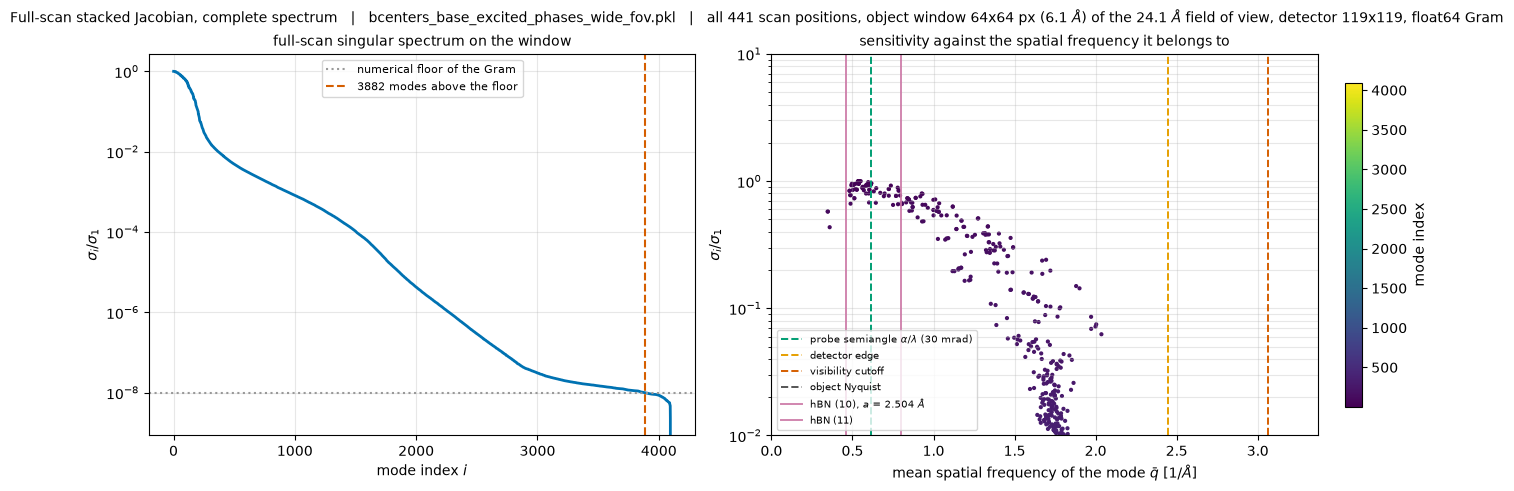

In [9]:
window_frequency_axis_inv_ang = np.fft.fftshift(
    np.fft.fftfreq(GRAM_WINDOW_WIDTH_PX, d=object_sampling_ang[0])
)
window_frequency_radius_inv_ang = np.hypot(
    *np.meshgrid(window_frequency_axis_inv_ang, window_frequency_axis_inv_ang, indexing="ij")
)
mode_power_spectrum = np.abs(np.fft.fftshift(np.fft.fft2(window_modes), axes=(-2, -1))) ** 2
mode_power_spectrum /= mode_power_spectrum.sum(axis=(-2, -1), keepdims=True)
mode_mean_frequency_inv_ang = (
    mode_power_spectrum * window_frequency_radius_inv_ang
).sum(axis=(-2, -1))

# Where the specimen's own periodicity sits, against the instrument's band limits.  The
# lattice constant is written down for this specimen rather than fitted from the data:
# these lines are annotation, and nothing downstream depends on them.
HBN_LATTICE_CONSTANT_ANG = 2.504        # in-plane a of hexagonal BN [A]
lattice_first_order_inv_ang = 2.0 / (np.sqrt(3.0) * HBN_LATTICE_CONSTANT_ANG)
lattice_second_order_inv_ang = 2.0 / HBN_LATTICE_CONSTANT_ANG
print(f"probe semiangle {PROBE_SEMIANGLE_MRAD:.0f} mrad / lambda {electron_wavelength_ang:.5f} A"
      f"  ->  alpha/lambda = {aperture_radius_inv_ang:.3f} 1/A")
print(f"hBN a = {HBN_LATTICE_CONSTANT_ANG:.3f} A  ->  (10) at "
      f"{lattice_first_order_inv_ang:.3f} 1/A (d = {1 / lattice_first_order_inv_ang:.3f} A),"
      f"  (11) at {lattice_second_order_inv_ang:.3f} 1/A")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)
mode_index = np.arange(1, n_window_pixels + 1)

axes[0].semilogy(mode_index, singular_values_window / singular_values_window[0],
                 color="#0072B2", linewidth=2.0)
axes[0].axhline(numerical_floor / singular_values_window[0], color="#999999", linestyle=":",
                linewidth=1.5, label="numerical floor of the Gram")
axes[0].axvline(n_above_floor, color="#D55E00", linestyle="--", linewidth=1.5,
                label=f"{n_above_floor} modes above the floor")
axes[0].set_xlabel("mode index $i$")
axes[0].set_ylabel("$\\sigma_i / \\sigma_1$")
axes[0].set_title("full-scan singular spectrum on the window", fontsize=10)
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, which="both")

scatter = axes[1].scatter(mode_mean_frequency_inv_ang,
                          singular_values_window / singular_values_window[0],
                          c=mode_index, cmap="viridis", s=4.0)
axes[1].set_yscale("log")
# instrument band limits, dashed
for frequency, label, color in [
    (aperture_radius_inv_ang,
     f"probe semiangle $\\alpha/\\lambda$ ({PROBE_SEMIANGLE_MRAD:.0f} mrad)", "#009E73"),
    (detector_edge_inv_ang, "detector edge", "#E69F00"),
    (visibility_cutoff_inv_ang, "visibility cutoff", "#D55E00"),
    (object_nyquist_inv_ang, "object Nyquist", "#555555"),
]:
    axes[1].axvline(frequency, color=color, linestyle="--", linewidth=1.4, label=label)
# specimen periodicity, solid, so it reads as a property of the sample not the microscope
for frequency, label in [
    (lattice_first_order_inv_ang,
     f"hBN (10), $a$ = {HBN_LATTICE_CONSTANT_ANG:.3f} $\\AA$"),
    (lattice_second_order_inv_ang, "hBN (11)"),
]:
    axes[1].axvline(frequency, color="#CC79A7", linestyle="-", linewidth=1.4, alpha=0.9,
                    label=label)
axes[1].axhline(numerical_floor / singular_values_window[0], color="#999999", linestyle=":",
                linewidth=1.5)
axes[1].set_xlabel("mean spatial frequency of the mode $\\bar q$ [1/$\\AA$]")
axes[1].set_ylabel("$\\sigma_i / \\sigma_1$")
axes[1].set_title("sensitivity against the spatial frequency it belongs to", fontsize=10)
axes[1].legend(fontsize=7.5, loc="lower left")
axes[1].grid(alpha=0.3, which="both")
axes[1].set_xlim(0.0, 1.1 * visibility_cutoff_inv_ang)
axes[1].set_ylim(1e-2, 10)
fig.colorbar(scatter, ax=axes[1], shrink=0.85, label="mode index")

fig.suptitle(
    f"Full-scan stacked Jacobian, complete spectrum   |   {PHASE_CACHE_PATH.name}   |   "
    f"all {n_scan_positions} scan positions, object window {GRAM_WINDOW_WIDTH_PX}x"
    f"{GRAM_WINDOW_WIDTH_PX} px ({GRAM_WINDOW_WIDTH_PX * object_sampling_ang[0]:.1f} $\\AA$) "
    f"of the {field_of_view_ang[0]:.1f} $\\AA$ field of view, detector "
    f"{n_detector_y}x{n_detector_x}, {'float64' if GRAM_USE_FLOAT64 else 'float32'} Gram",
    fontsize=10,
)
plt.show()

### The modes at both ends

Top row: the perturbations inside the window that the whole scan sees **best**. Bottom
row: the ones it sees **worst** among those still above the numerical floor - the
directions a reconstruction will recover last, or not at all.

Each row shares one symmetric colour scale, so faintness within a row is real.

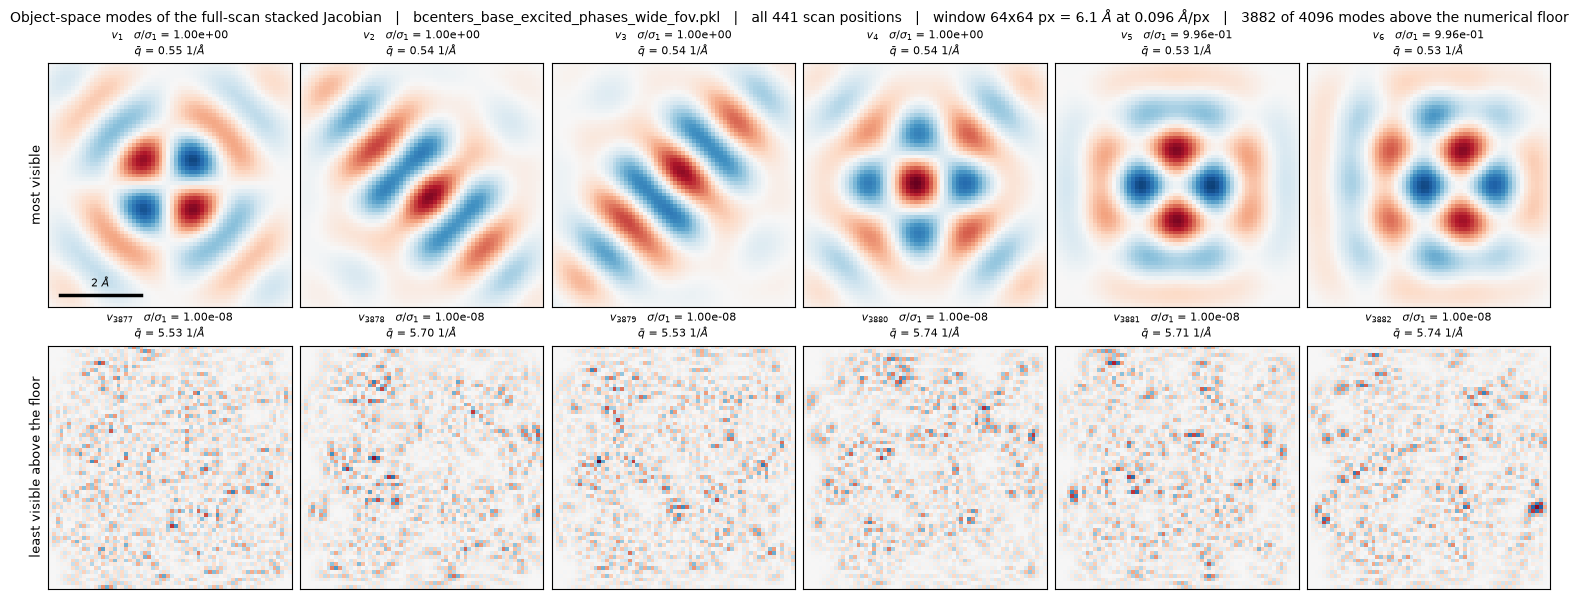

In [10]:
window_extent_ang = [
    float(object_x_ang[gram_window_origin[1]]),
    float(object_x_ang[gram_window_origin[1] + GRAM_WINDOW_WIDTH_PX - 1]),
    float(object_y_ang[gram_window_origin[0]]),
    float(object_y_ang[gram_window_origin[0] + GRAM_WINDOW_WIDTH_PX - 1]),
]
leading_indices = list(range(N_MODES_SHOWN))
trailing_indices = list(range(n_above_floor - N_MODES_SHOWN, n_above_floor))

fig, axes = plt.subplots(2, N_MODES_SHOWN, figsize=(2.55 * N_MODES_SHOWN, 5.9),
                         constrained_layout=True)
for row, (indices, row_label) in enumerate([
    (leading_indices, "most visible"),
    (trailing_indices, "least visible above the floor"),
]):
    row_limit = float(np.abs(window_modes[indices]).max())
    for column, mode_number in enumerate(indices):
        ax = axes[row, column]
        ax.imshow(window_modes[mode_number], extent=window_extent_ang, origin="lower",
                  cmap="RdBu_r", vmin=-row_limit, vmax=row_limit, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(
            f"$v_{{{mode_number + 1}}}$   $\\sigma/\\sigma_1$ = "
            f"{singular_values_window[mode_number] / singular_values_window[0]:.2e}\n"
            f"$\\bar q$ = {mode_mean_frequency_inv_ang[mode_number]:.2f} 1/$\\AA$",
            fontsize=8,
        )
    axes[row, 0].set_ylabel(row_label, fontsize=9)

scale_bar_ang = 2.0
axes[0, 0].plot([window_extent_ang[0] + 0.3, window_extent_ang[0] + 0.3 + scale_bar_ang],
                [window_extent_ang[2] + 0.3] * 2, color="black", linewidth=2.5)
axes[0, 0].text(window_extent_ang[0] + 0.3 + scale_bar_ang / 2, window_extent_ang[2] + 0.42,
                f"{scale_bar_ang:.0f} $\\AA$", ha="center", va="bottom", fontsize=8)

fig.suptitle(
    f"Object-space modes of the full-scan stacked Jacobian   |   {PHASE_CACHE_PATH.name}   |   "
    f"all {n_scan_positions} scan positions   |   window {GRAM_WINDOW_WIDTH_PX}x"
    f"{GRAM_WINDOW_WIDTH_PX} px = {GRAM_WINDOW_WIDTH_PX * object_sampling_ang[0]:.1f} $\\AA$ "
    f"at {object_sampling_ang[0]:.3f} $\\AA$/px   |   {n_above_floor} of {n_window_pixels} "
    f"modes above the numerical floor",
    fontsize=10,
)
plt.show()

## The whole scan at full object resolution

The window above bounds the perturbation to a few Angstrom. Dropping that restriction
means going matrix-free: randomized subspace iteration on $A$ and $A^{\mathsf T}$ over the
whole field of view, which reaches the leading modes only but puts no constraint on where
in the object they live.

If the leading modes come out confined near the centre of the field of view, the window
above was not restrictive; if they spread, the window was. Either way $\\sigma_1$ from the
two routes should agree, since the best mode of the whole object cannot be weaker than the
best mode of a window inside it.

**Expect the top of this spectrum to be degenerate.** Over a field of view many times the
probe width, a perturbation at the most-visible spatial frequency is equally visible
wherever it sits and at whatever orientation, so hundreds of modes share $\\sigma_1$ to
within a fraction of a percent. Inside a degenerate subspace the individual vectors are
set by the random seed and mean nothing on their own - the panels below are one arbitrary
basis of it. Read $\\sigma_1$, the degeneracy count and $\\bar q$; do not read the
speckle.

In [11]:
n_sketch = FULL_RESOLUTION_N_MODES + FULL_RESOLUTION_N_OVERSAMPLE


def stacked_matvec_batch(object_perturbations):
    """``A h`` for a batch: ``(k, n_y, n_x)`` -> ``(M, k, det_y, det_x)``, chunked over scan."""
    n_batch = object_perturbations.shape[0]
    response = torch.empty(n_scan_positions, n_batch, n_detector_y, n_detector_x,
                           device=TORCH_DEVICE, dtype=torch.float64)
    for start in range(0, n_scan_positions, SCAN_CHUNK_SIZE):
        chunk = slice(start, min(start + SCAN_CHUNK_SIZE, n_scan_positions))
        response[chunk] = -2.0 * (
            torch.conj(camera_wave_by_scan[chunk])[:, None]
            * crop_to_detector(centered_dft_torch(
                exit_wave_by_scan[chunk][:, None] * object_perturbations[None]))
        ).imag
    return response


def stacked_rmatvec_batch(detector_fields):
    """``A^T g`` for a batch: ``(M, k, det_y, det_x)`` -> ``(k, n_y, n_x)``."""
    n_batch = detector_fields.shape[1]
    accumulator = torch.zeros(n_batch, n_object_y, n_object_x,
                              device=TORCH_DEVICE, dtype=torch.float64)
    for start in range(0, n_scan_positions, SCAN_CHUNK_SIZE):
        chunk = slice(start, min(start + SCAN_CHUNK_SIZE, n_scan_positions))
        weighted = 1j * detector_fields[chunk] * torch.conj(camera_wave_by_scan[chunk])[:, None]
        padded = torch.zeros(weighted.shape[0], n_batch, n_object_y, n_object_x,
                             device=TORCH_DEVICE, dtype=torch.complex128)
        padded[..., detector_row_start:detector_row_start + n_detector_y,
               detector_col_start:detector_col_start + n_detector_x] = weighted
        accumulator += (2.0 * (exit_wave_by_scan[chunk][:, None] * centered_dft_torch(padded)).real).sum(0)
    return accumulator


def to_object_basis(flat_columns):
    return flat_columns.T.reshape(n_sketch, n_object_y, n_object_x)


def to_detector_basis(flat_columns):
    return flat_columns.T.reshape(n_sketch, n_scan_positions, n_detector_y, n_detector_x
                                  ).permute(1, 0, 2, 3).contiguous()


generator = torch.Generator(device=TORCH_DEVICE).manual_seed(RANDOM_SEED)
random_detector_sketch = torch.randn(
    n_scan_positions, n_sketch, n_detector_y, n_detector_x,
    device=TORCH_DEVICE, dtype=torch.float64, generator=generator,
)
object_basis = torch.linalg.qr(
    stacked_rmatvec_batch(random_detector_sketch).reshape(n_sketch, -1).T
)[0]
del random_detector_sketch

start_time = time.time()
for iteration in range(FULL_RESOLUTION_N_ITERATIONS):
    detector_basis = torch.linalg.qr(
        stacked_matvec_batch(to_object_basis(object_basis)).permute(1, 0, 2, 3).reshape(n_sketch, -1).T
    )[0]
    object_basis = torch.linalg.qr(
        stacked_rmatvec_batch(to_detector_basis(detector_basis)).reshape(n_sketch, -1).T
    )[0]
    print(f"  subspace iteration {iteration + 1}/{FULL_RESOLUTION_N_ITERATIONS}   "
          f"({time.time() - start_time:5.1f} s)")

projected = stacked_matvec_batch(to_object_basis(object_basis)).permute(1, 0, 2, 3).reshape(n_sketch, -1).T
_, projected_singular_values, projected_right_t = torch.linalg.svd(projected, full_matrices=False)
full_resolution_modes = (object_basis @ projected_right_t.T).T[:FULL_RESOLUTION_N_MODES]
full_resolution_modes = full_resolution_modes.reshape(FULL_RESOLUTION_N_MODES, n_object_y, n_object_x)
flat_modes = full_resolution_modes.reshape(FULL_RESOLUTION_N_MODES, -1)
peak_sign = torch.sign(flat_modes.gather(1, flat_modes.abs().argmax(1, keepdim=True)))
full_resolution_modes = (full_resolution_modes * peak_sign[:, None]).cpu().numpy()
full_resolution_singular_values = projected_singular_values[:FULL_RESOLUTION_N_MODES].cpu().numpy()

object_frequency_axis_inv_ang = np.fft.fftshift(np.fft.fftfreq(n_object_y, d=object_sampling_ang[0]))
object_frequency_radius_inv_ang = np.hypot(
    *np.meshgrid(object_frequency_axis_inv_ang, object_frequency_axis_inv_ang, indexing="ij")
)
full_mode_power = np.abs(np.fft.fftshift(np.fft.fft2(full_resolution_modes), axes=(-2, -1))) ** 2
full_mode_power /= full_mode_power.sum(axis=(-2, -1), keepdims=True)
full_resolution_mean_frequency_inv_ang = (
    full_mode_power * object_frequency_radius_inv_ang
).sum(axis=(-2, -1))

sketch_singular_values = projected_singular_values.cpu().numpy()
n_within_one_percent = int((sketch_singular_values > 0.99 * sketch_singular_values[0]).sum())
print(f"\nfull-resolution leading modes in {time.time() - start_time:.1f} s")
degeneracy_note = ("   <- degenerate: read sigma and qbar, not the individual panels"
                   if n_within_one_percent > 2 else "")
print(f"sigma within 1% of sigma_1 : {n_within_one_percent} of the {n_sketch} sketch "
      f"vectors{degeneracy_note}")
print(f"sketch size                : {n_sketch} vectors over "
      f"{n_object_y * n_object_x} object pixels")
for mode_number in range(FULL_RESOLUTION_N_MODES):
    print(f"   v_{mode_number + 1}  sigma = {full_resolution_singular_values[mode_number]:.4e}"
          f"   sigma/sigma_1 = "
          f"{full_resolution_singular_values[mode_number] / full_resolution_singular_values[0]:.4f}"
          f"   qbar = {full_resolution_mean_frequency_inv_ang[mode_number]:.3f} 1/A")

  subspace iteration 1/6   (  1.1 s)
  subspace iteration 2/6   (  3.4 s)
  subspace iteration 3/6   (  5.7 s)
  subspace iteration 4/6   (  8.0 s)
  subspace iteration 5/6   ( 10.3 s)
  subspace iteration 6/6   ( 12.6 s)


[W1012 13:29:16.011811263 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 16187916288 bytes (free: 13940752384, total: 33668268032).



full-resolution leading modes in 15.2 s
sigma within 1% of sigma_1 : 16 of the 68 sketch vectors   <- degenerate: read sigma and qbar, not the individual panels
sketch size                : 68 vectors over 63001 object pixels
   v_1  sigma = 6.4949e-03   sigma/sigma_1 = 1.0000   qbar = 0.546 1/A
   v_2  sigma = 6.4923e-03   sigma/sigma_1 = 0.9996   qbar = 0.549 1/A
   v_3  sigma = 6.4895e-03   sigma/sigma_1 = 0.9992   qbar = 0.543 1/A
   v_4  sigma = 6.4836e-03   sigma/sigma_1 = 0.9983   qbar = 0.546 1/A
   v_5  sigma = 6.4791e-03   sigma/sigma_1 = 0.9976   qbar = 0.546 1/A
   v_6  sigma = 6.4761e-03   sigma/sigma_1 = 0.9971   qbar = 0.547 1/A
   v_7  sigma = 6.4723e-03   sigma/sigma_1 = 0.9965   qbar = 0.550 1/A
   v_8  sigma = 6.4675e-03   sigma/sigma_1 = 0.9958   qbar = 0.551 1/A


In [ ]:
# The modes are solved over the whole object grid with no spatial restriction, so the
# only thing that sets where they live is where the scan illuminates.  Mark the scan
# positions so that can be read off the figure rather than assumed.
scan_extent_object_frame_ang = [
    float(scan_positions_flat_xy_ang[:, 0].min() + object_x_ang[0]),
    float(scan_positions_flat_xy_ang[:, 0].max() + object_x_ang[0]),
    float(scan_positions_flat_xy_ang[:, 1].min() + object_y_ang[0]),
    float(scan_positions_flat_xy_ang[:, 1].max() + object_y_ang[0]),
]

n_columns = min(4, FULL_RESOLUTION_N_MODES)
n_rows = int(np.ceil(FULL_RESOLUTION_N_MODES / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(3.3 * n_columns, 3.6 * n_rows),
                         constrained_layout=True)
axes = np.atleast_2d(axes)
# A robust limit: a single hot pixel in one mode must not flatten every other panel.
shared_limit = float(np.percentile(np.abs(full_resolution_modes), 99.9))
print(f"colour limit (99.9th percentile) = {shared_limit:.4f}, "
      f"peak |v| = {np.abs(full_resolution_modes).max():.4f}")

for mode_number in range(FULL_RESOLUTION_N_MODES):
    ax = axes.ravel()[mode_number]
    handle = ax.imshow(full_resolution_modes[mode_number], extent=object_extent_ang,
                       origin="lower", cmap="RdBu_r", vmin=-shared_limit, vmax=shared_limit,
                       interpolation="nearest")
    ax.add_patch(plt.Rectangle(
        (scan_extent_object_frame_ang[0], scan_extent_object_frame_ang[2]),
        scan_extent_object_frame_ang[1] - scan_extent_object_frame_ang[0],
        scan_extent_object_frame_ang[3] - scan_extent_object_frame_ang[2],
        fill=False, edgecolor="#D55E00", linewidth=1.6, linestyle="--",
    ))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"$v_{{{mode_number + 1}}}$   $\\sigma$ = "
                 f"{full_resolution_singular_values[mode_number]:.3e}\n"
                 f"$\\bar q$ = {full_resolution_mean_frequency_inv_ang[mode_number]:.2f} 1/$\\AA$",
                 fontsize=9)
for extra_axis in axes.ravel()[FULL_RESOLUTION_N_MODES:]:
    extra_axis.axis("off")

scale_bar_ang = 5.0
axes[0, 0].plot([object_extent_ang[0] + 1.0, object_extent_ang[0] + 1.0 + scale_bar_ang],
                [object_extent_ang[2] + 1.0] * 2, color="black", linewidth=2.5)
axes[0, 0].text(object_extent_ang[0] + 1.0 + scale_bar_ang / 2, object_extent_ang[2] + 1.4,
                f"{scale_bar_ang:.0f} $\\AA$", ha="center", va="bottom", fontsize=8)
fig.colorbar(handle, ax=axes, shrink=0.75, extend="both",
             label="mode amplitude (unit-norm modes, 99.9th-percentile limit)")

fig.suptitle(
    f"Leading modes of the full-scan stacked Jacobian, full resolution   |   "
    f"{PHASE_CACHE_PATH.name}\n"
    f"{n_scan_positions} scan positions   |   field of view {field_of_view_ang[0]:.1f} x "
    f"{field_of_view_ang[1]:.1f} $\\AA$ at {object_sampling_ang[0]:.3f} $\\AA$/px   |   "
    f"matrix-free, {n_sketch}-vector sketch, {FULL_RESOLUTION_N_ITERATIONS} iterations, "
    f"seed {RANDOM_SEED}\n"
    f"dashed orange: scan region {scan_extent_object_frame_ang[0]:.1f}-"
    f"{scan_extent_object_frame_ang[1]:.1f} $\\AA$ (probe centres) - the modes are "
    f"unconstrained over the full grid, so their support is set by the scan",
    fontsize=9,
)
plt.show()

## Summary

In [12]:
print(f"phase cache            : {PHASE_CACHE_PATH.name}")
print(f"scan                   : {scan_shape} = {n_scan_positions} positions at "
      f"{realised_scan_step_ang:.3f} A over {SCAN_REGION_START} to {SCAN_REGION_END} A")
print(f"stacked operator A     : {dense_stack_shape[0]:,} x {dense_stack_shape[1]:,} "
      f"({n_scan_positions} positions x {n_detector_y}x{n_detector_x} detector pixels, "
      f"{n_object_y}x{n_object_x} object pixels)")
print(f"Gram route             : structured (two FFTs per position), "
      f"{'float64' if GRAM_USE_FLOAT64 else 'float32'}, symmetric={GRAM_SYMMETRIC}")
print()
print(f"window spectrum        : {n_above_floor}/{n_window_pixels} modes above the "
      f"{'1e-8' if GRAM_USE_FLOAT64 else '1e-5'} numerical floor")
print(f"   sigma_1             : {singular_values_window[0]:.4e}   at qbar = "
      f"{mode_mean_frequency_inv_ang[0]:.3f} 1/A")
print(f"   faintest resolved   : {singular_values_window[n_above_floor - 1]:.4e}   at qbar = "
      f"{mode_mean_frequency_inv_ang[n_above_floor - 1]:.3f} 1/A")
print(f"   median qbar of the 1% strongest modes  : "
      f"{np.median(mode_mean_frequency_inv_ang[:max(1, n_window_pixels // 100)]):.3f} 1/A")
print(f"   median qbar of the modes below the floor: "
      f"{np.median(mode_mean_frequency_inv_ang[n_above_floor:]):.3f} 1/A")
print()
print(f"band limits            : aperture {aperture_radius_inv_ang:.3f}, "
      f"detector edge {detector_edge_inv_ang:.3f}, visibility cutoff "
      f"{visibility_cutoff_inv_ang:.3f}, object Nyquist {object_nyquist_inv_ang:.3f} 1/A")
print(f"full-resolution sigma_1: {full_resolution_singular_values[0]:.4e}   at qbar = "
      f"{full_resolution_mean_frequency_inv_ang[0]:.3f} 1/A")

phase cache            : bcenters_base_excited_phases_wide_fov.pkl
scan                   : (21, 21) = 441 positions at 0.500 A over (7, 7) to (17, 17) A
stacked operator A     : 6,245,001 x 63,001 (441 positions x 119x119 detector pixels, 251x251 object pixels)
Gram route             : structured (two FFTs per position), float64, symmetric=True

window spectrum        : 3882/4096 modes above the 1e-8 numerical floor
   sigma_1             : 6.4635e-03   at qbar = 0.551 1/A
   faintest resolved   : 6.4665e-11   at qbar = 5.739 1/A
   median qbar of the 1% strongest modes  : 0.540 1/A
   median qbar of the modes below the floor: 5.684 1/A

band limits            : aperture 0.617, detector edge 2.449, visibility cutoff 3.065, object Nyquist 5.208 1/A
full-resolution sigma_1: 6.4949e-03   at qbar = 0.546 1/A


## How to read this

* **The spectrum has two blind ends, not one.** A constant phase is exactly null (premise
  check 3), and so is everything above the visibility cutoff $q_{\max} + \alpha/\lambda$.
  The scan is a band-pass on object phase, and the pass band is what any reconstruction
  from this geometry can contain.
* **The leading modes sit near the aperture frequency $\alpha/\lambda$**, not at zero
  frequency. Sensitivity peaks where the scattered wave interferes with the bright-field
  disc over the largest area, which is the standard ptychographic transfer argument
  arriving here as a property of the operator rather than as an assumption.
* **The count of modes above the floor is a numerics statement, not a physics one.**
  Forming the Gram costs half the digits, so the trailing end of the spectrum is reported
  down to $\sim 10^{-8}\sigma_1$ and no further. Read the position of the roll-off in
  $\bar q$, which is stable, rather than the exact rank.
* **The scan's own bookkeeping is part of the operator.** Duplicate positions and uneven
  coverage both re-weight $A^{\mathsf T}A$, and the leading modes will report that
  weighting before they report anything about the optics. Check the coverage panel before
  reading the modes.
* **Window versus full resolution.** The windowed spectrum is complete but confines the
  perturbation; the matrix-free run is unconfined but only reaches the leading modes. They
  agree where they overlap only if the leading modes really are localised - which is what
  the dashed window on the full-resolution figure is there to let you check.

### What this does not establish

The small singular values here are the directions a *noiseless* measurement cannot
separate. Adding Poisson noise at a finite dose raises the effective floor far above the
numerical one, so the practical blind subspace is much larger than the null space of $A$.
That is a separate calculation - it needs the dose and the noise covariance - and it
belongs in its own notebook.